In [231]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import(
                             accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             confusion_matrix,
                             roc_auc_score
)

from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers



In [232]:
# check version

print("Tensorflow version: ", tf.__version__)
print("Keras version: ", keras.__version__)

Tensorflow version:  2.21.0
Keras version:  3.15.1


In [233]:
# Load Dataset

df = pd.read_csv("email_spam_dataset_v2.csv")

In [234]:
df.head()

,Subject,Message,Spam/Ham,Date
0,Schedule confirmation,Could you please check the attached document? ...,ham,2024-12-02 07:15:00
1,Project deadline,"Hi Neha, I have shared the travel details for ...",ham,2024-01-15 18:41:00
2,Earn money from home,Congratulations! You have been selected for a ...,spam,2024-05-10 15:04:00
3,Claim your reward today,Special clearance sale with prices reduced by ...,spam,2025-02-12 20:31:00
4,Last chance to claim,Congratulations! You have been selected for a ...,spam,2024-01-14 07:06:00


In [235]:
# Understand Dataset

df.shape

(5000, 4)

In [236]:
df.columns

Index(['Subject', 'Message', 'Spam/Ham', 'Date'], dtype='str')

In [237]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Subject   5000 non-null   str  
 1   Message   5000 non-null   str  
 2   Spam/Ham  5000 non-null   str  
 3   Date      5000 non-null   str  
dtypes: str(4)
memory usage: 156.4 KB


In [238]:
df['Spam/Ham'].value_counts()

Spam/Ham
ham     2500
spam    2500
Name: count, dtype: int64

In [239]:
df.isnull().sum()

Subject     0
Message     0
Spam/Ham    0
Date        0
dtype: int64

In [240]:
# Subject + message as input feature

df['text'] = (df['Subject'].fillna("") + " " +df['Message'].fillna(""))

In [241]:
df[['Subject','Message','text']].head()

,Subject,Message,text
0,Schedule confirmation,Could you please check the attached document? ...,Schedule confirmation Could you please check t...
1,Project deadline,"Hi Neha, I have shared the travel details for ...","Project deadline Hi Neha, I have shared the tr..."
2,Earn money from home,Congratulations! You have been selected for a ...,Earn money from home Congratulations! You have...
3,Claim your reward today,Special clearance sale with prices reduced by ...,Claim your reward today Special clearance sale...
4,Last chance to claim,Congratulations! You have been selected for a ...,Last chance to claim Congratulations! You have...


In [242]:
# Create target variable

df["label"] = df["Spam/Ham"].map({"ham":0,"spam":1})

In [243]:
df["label"].value_counts()

label
0    2500
1    2500
Name: count, dtype: int64

In [244]:
# Remove Unnecessary columns
df = df[["text","label"]]

In [245]:
df.head()

,text,label
0,Schedule confirmation Could you please check t...,0
1,"Project deadline Hi Neha, I have shared the tr...",0
2,Earn money from home Congratulations! You have...,1
3,Claim your reward today Special clearance sale...,1
4,Last chance to claim Congratulations! You have...,1


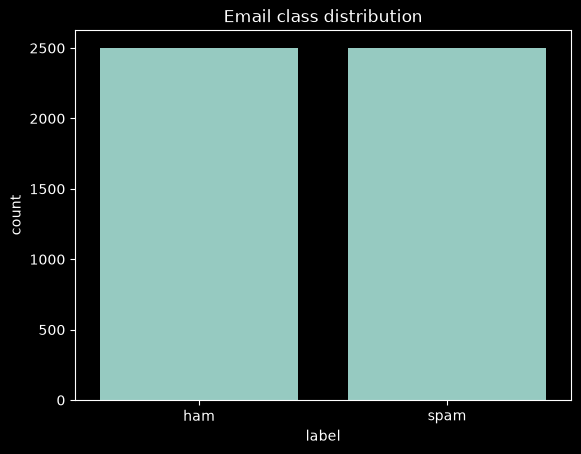

In [246]:
# Check class distribution
sns.countplot(x="label",data=df)

plt.xticks(
    [0,1],
    ["ham","spam"]
)

plt.title("Email class distribution")
plt.show()

In [247]:
# Remove duplicate emails
df = df.drop_duplicates()

print("Dataset shape : ", df.shape)

Dataset shape :  (2136, 2)


In [248]:
# Train/test split
X = df["text"]
y = df["label"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
# to make sure the training and testing sets have the exact same percentage of each class label as the original dataset

In [249]:
# TF IDF(text to numbers)
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words='english',
    ngram_range=(1,2)
)

In [250]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [251]:
X_test_tfidf = tfidf.transform(X_test)

In [252]:
print("Training shape : ", X_train_tfidf.shape)
print("Test shape : ", X_test_tfidf.shape)

Training shape :  (1708, 1242)
Test shape :  (428, 1242)


In [253]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive  # tells XGBoost to give more importance to the positive class (Spam) during training.

print(scale_pos_weight)

2.111111111111111


In [254]:
# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100, # Number of trees.
    max_depth=6,  # Maximum depth of each tree
    learning_rate=0.05, # How strongly each new tree contributes.
    scale_pos_weight=scale_pos_weight,
    subsample=0.8, # Percentage of training samples used by each tree.
    colsample_bytree=0.8, # Percentage of features used by each tree.
    random_state=42,
    eval_metric="logloss",
)

In [255]:
# Train XGBoost model
xgb_model.fit(
    X_train_tfidf,
    y_train
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [256]:
# Prediction
y_pred_xgb = xgb_model.predict(X_test_tfidf)

In [257]:
# Accuracy
accuracy_xgb = accuracy_score(
    y_test,
    y_pred_xgb
)

print("XGBoost Accuracy : ", accuracy_xgb)

XGBoost Accuracy :  1.0


In [258]:
# Precision
precision_xgb = precision_score(
    y_test,
    y_pred_xgb
)

print("XGBoost Precision:", precision_xgb)

XGBoost Precision: 1.0


In [259]:
print(y_pred_xgb)

[0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 1
 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 0 1 1 0 0 1 1 1 0 0 1 0 1 0 0
 1 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 1 0 0 0 0 1 1 1 0 1 1 0 0 1 1 0 0 0 0 0 0
 1 1 0 1 0 0 1 1 0 0 1 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0
 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 1 1
 0 0 1 0 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 0 0 1 1
 1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 0
 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 1 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0
 0 1 1 0 0 0 0 0 1 1 1 1 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 1 0 1 1 1 0 0 0 1 0 1 0 0 1 0 0 0 1 0]


In [260]:
# Recall
recall_xgb = recall_score(
    y_test,
    y_pred_xgb
)

print("XGBoost Recall:", recall_xgb)

XGBoost Recall: 1.0


In [261]:
# F1-Score
f1_xgb = f1_score(
    y_test,
    y_pred_xgb
)

print("XGBoost F1 Score:", f1_xgb)

XGBoost F1 Score: 1.0


In [262]:
# Classification Report
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00       290
        Spam       1.00      1.00      1.00       138

    accuracy                           1.00       428
   macro avg       1.00      1.00      1.00       428
weighted avg       1.00      1.00      1.00       428



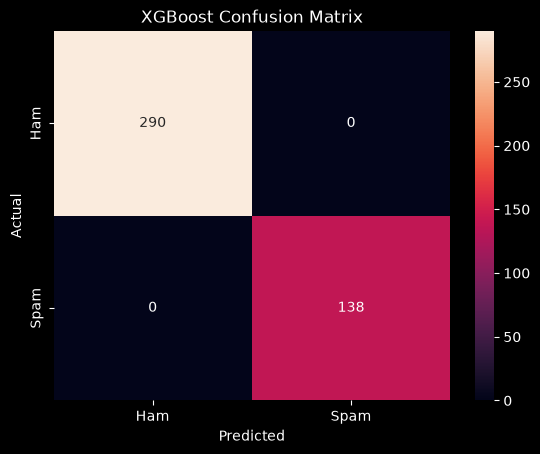

In [ ]:
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.show()

In [264]:
y_prob_xgb = xgb_model.predict_proba(
    X_test_tfidf
)[:, 1]

roc_auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)

print("XGBoost ROC-AUC:", roc_auc_xgb)

XGBoost ROC-AUC: 0.9999999999999999


#### DL

In [265]:
# TensorFlow Dense layers generally work conveniently with dense arrays for this experiment.
X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

print(X_train_dense.shape)

(1708, 1242)


In [266]:
# Build ANN
model = keras.Sequential([

    keras.Input(
        shape=(X_train_dense.shape[1],)
    ),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

In [267]:
# Compile
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [268]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │       159,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,425 (654.00 KB)

 Trainable params: 167,425 (654.00 KB)

 Non-trainable params: 0 (0.00 B)

In [269]:
# Train
history = model.fit(
    X_train_dense,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8448 - loss: 0.4815 - val_accuracy: 1.0000 - val_loss: 0.1643
Epoch 2/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9993 - loss: 0.0574 - val_accuracy: 1.0000 - val_loss: 0.0073
Epoch 3/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 4/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 7.8828e-04
Epoch 5/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 4.5577e-04
Epoch 6/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 7.3296e-04 - val_accuracy: 1.0000 - val_loss: 3.0331e-04
Epoch 7/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 5.5085e-04 - val_accuracy: 1.0000 - val_loss: 2.1374e-04
Epoch 8/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 4.5010e-04 - val_

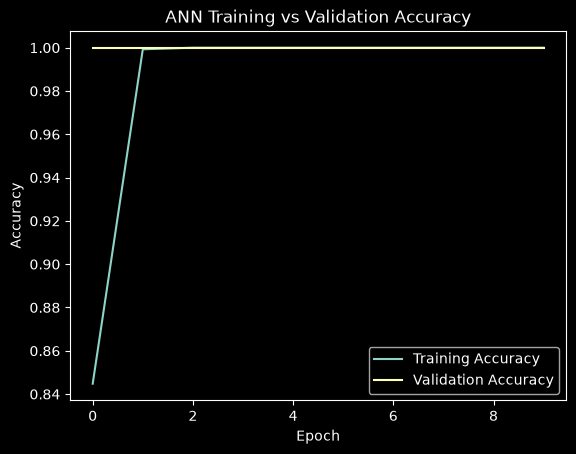

In [270]:
# Plot training accuracy
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("ANN Training vs Validation Accuracy")

plt.legend()

plt.show()

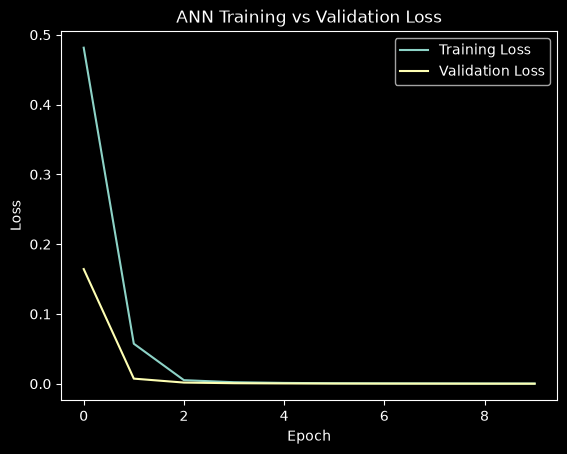

In [271]:
# Plot loss

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("ANN Training vs Validation Loss")

plt.legend()

plt.show()

In [272]:
y_prob_ann = model.predict(
    X_test_dense
)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [273]:
y_pred_ann = (
    y_prob_ann >= 0.5
).astype(int)

In [274]:
# ANN Accuracy
accuracy_ann = accuracy_score(
    y_test,
    y_pred_ann
)

print("ANN Accuracy:", accuracy_ann)

ANN Accuracy: 1.0


In [275]:
# ANN Classification Report
print(
    classification_report(
        y_test,
        y_pred_ann,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00       290
        Spam       1.00      1.00      1.00       138

    accuracy                           1.00       428
   macro avg       1.00      1.00      1.00       428
weighted avg       1.00      1.00      1.00       428



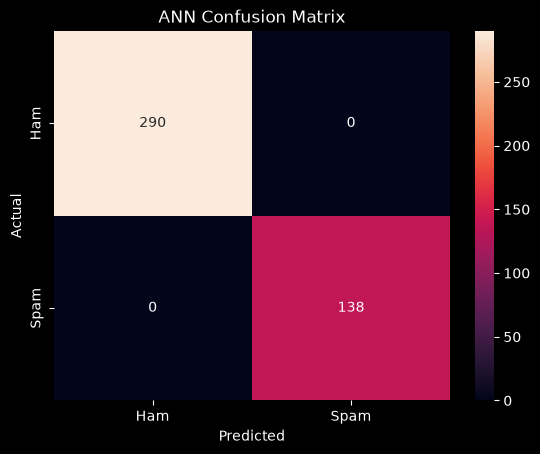

In [276]:
# ANN Confusion Matrix
cm_ann = confusion_matrix(
    y_test,
    y_pred_ann
)

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("ANN Confusion Matrix")

plt.show()

In [277]:
# ANN ROC-AUC
roc_auc_ann = roc_auc_score(
    y_test,
    y_prob_ann
)

print("ANN ROC-AUC:", roc_auc_ann)

ANN ROC-AUC: 1.0


In [280]:
# Compare XGBoost vs ANN
results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "ANN"
    ],

    "Accuracy": [
        accuracy_xgb,
        accuracy_ann
    ],

    "Precision": [
        precision_xgb,
        precision_score(y_test, y_pred_ann)
    ],

    "Recall": [
        recall_xgb,
        recall_score(y_test, y_pred_ann)
    ],

    "F1 Score": [
        f1_xgb,
        f1_score(y_test, y_pred_ann)
    ],

    "ROC-AUC": [
        roc_auc_xgb,
        roc_auc_ann
    ]
})

In [281]:
results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,1.0,1.0,1.0,1.0,1.0
1,ANN,1.0,1.0,1.0,1.0,1.0
